In [17]:
from langgraph.graph import MessagesState
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.graph import StateGraph, START
from langgraph.checkpoint.memory import InMemorySaver

In [18]:
load_dotenv()

True

In [19]:
model = ChatGroq(model="openai/gpt-oss-120b")

In [20]:
class ChatState(MessagesState):
    summary: str

In [21]:
def summarize_conversation(state: ChatState):

    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }

In [22]:
def chat_node(state: ChatState):
    messages = []

    if state["summary"]:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{state['summary']}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = model.invoke(messages)
    return {"messages": [response]}

In [23]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [24]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

builder.add_edge(START, "chat")

builder.add_conditional_edges(
    "chat",
    should_summarize,
    {
        True: "summarize",
        False: "__end__",
    }
)

builder.add_edge("summarize", "__end__")



In [25]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

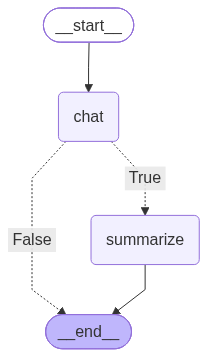

In [26]:
graph

In [27]:
config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    out = graph.invoke({"messages": [HumanMessage(content=text)], "summary": ""}, config=config)
    return out

In [28]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [29]:
run_turn('Quantum Physics')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='472150b8-5712-4cc8-b047-b0b1a0ca1ffa')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Physics
- AIMessage : ## Quantum Physics – A Quick‑Start Overview

Quantum physics (or quantum mechani


In [30]:
run_turn('How is Albert Einstien related?')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='472150b8-5712-4cc8-b047-b0b1a0ca1ffa'), AIMessage(content='## Quantum Physics – A Quick‑Start Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how the universe works at the smallest scales—atoms, electrons, photons, and other elementary particles. At those scales, the familiar “classical” laws of motion (Newton, Maxwell, etc.) no longer give accurate predictions, and a new set of principles takes over.\n\nBelow is a concise roadmap that will help you navigate the main ideas, historical milestones, and modern applications. Feel free to let me know which part you’d like to explore in more depth!\n\n---\n\n### 1. Core Concepts\n\n| Concept | What It Means | Famous Thought/Experiment |\n|---------|---------------|---------------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑like behavior. | 

In [31]:
run_turn('What are some of Einstien"s fampus work')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='472150b8-5712-4cc8-b047-b0b1a0ca1ffa'), AIMessage(content='## Quantum Physics – A Quick‑Start Overview\n\nQuantum physics (or quantum mechanics) is the branch of physics that describes how the universe works at the smallest scales—atoms, electrons, photons, and other elementary particles. At those scales, the familiar “classical” laws of motion (Newton, Maxwell, etc.) no longer give accurate predictions, and a new set of principles takes over.\n\nBelow is a concise roadmap that will help you navigate the main ideas, historical milestones, and modern applications. Feel free to let me know which part you’d like to explore in more depth!\n\n---\n\n### 1. Core Concepts\n\n| Concept | What It Means | Famous Thought/Experiment |\n|---------|---------------|---------------------------|\n| **Wave‑Particle Duality** | Particles (e.g., electrons, photons) exhibit both wave‑like and particle‑like behavior. | 

In [ ]:
run_turn('Explain special theory of relativity')
show_state()       